In [ ]:
import time, os, urllib.request # time = measure training time, os file checks, urllib = download
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

torch.manual_seed(21)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device)

Device: cuda


In [ ]:
URL = 'https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt'
if not os.path.exists('input.txt'):
    urllib.request.urlretrieve(URL, 'input.txt')
text = open('input.txt', encoding='utf-8').read()
print('Length of dataset in characters:', len(text))

chars = sorted(set(text))
vocab_size = len(chars)
stoi = {c: i for i, c in enumerate(chars)}  #character -> number
itos = {i: c for c, i in stoi.items()}  #number -> character
encode = lambda s: [stoi[c] for c in s]
decode = lambda l: ''.join([itos[i] for i in l])
print('Vocab size:', vocab_size)

data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))
train_data, val_data = data[:n], data[n:]   #validation text shouldn't be trained on
print('Train chars:', len(train_data), '| Val chars:', len(val_data))



Length of dataset in characters: 1115394
Vocab size: 65
Train chars: 1003854 | Val chars: 111540


In [ ]:
block_size = 128
batch_size = 64
max_iters = 3000
eval_interval = 250
eval_itrs = 100

def get_batch(split):
    d = train_data if split == 'train' else val_data
    ix = torch.randint(len(d) - block_size, (batch_size,))
    x = torch.stack([d[i:i+block_size] for i in ix])
    y = torch.stack([d[i+1:i+block_size+1] for i in ix]) #target = input by one: the next character
    return x.to(device), y.to(device)

@torch.no_grad()
def estimate_loss(model):
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_itrs)
        for k in range(eval_itrs):
            xb, yb = get_batch(split)
            _, loss = model(xb, yb)
            losses[k] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out

@torch.no_grad()
def generate(model, max_new_tokens=500, seed=0):
    model.eval()
    torch.manual_seed(seed)
    idx = torch.zeros((1, 1), dtype=torch.long, device=device)
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -block_size:]
        logits, _ = model(idx_cond)
        probs = F.softmax(logits[:, -1, :], dim=-1)   #scores -> probability of next character
        nxt = torch.multinomial(probs, num_samples=1) #sample one character
        idx = torch.cat([idx, nxt], dim=1)            #add and repeat
    model.train()
    return decode(idx[0].tolist())

results = {}

def train(model, name, lr):
    model.to(device)
    n_params = sum(p.numel() for p in model.parameters())
    print(f'--- {name}: {n_params} parameters ---')
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    history, eval_time = [], 0.0
    if device == 'cuda': torch.cuda.synchronize()
    start = time.time()
    for it in range(max_iters + 1):
        if it % eval_interval ==0:
            t0 = time.time()
            l = estimate_loss(model)
            eval_time += time.time() - t0   #evaluation time isn't the same as training time
            history.append((it, l['train'], l['val']))
            print (f"step {it:4d} | train loss {l['train']:.4f} | val loss {l['val']:.4f} | eval time {eval_time:.2f}")
        if it == max_iters:
            break
        xb, yb = get_batch('train')
        _, loss = model(xb, yb)   #forward pass
        opt.zero_grad(set_to_none=True)
        loss.backward()   #compute gradients
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()   #update parameters
    if device == 'cuda': torch.cuda.synchronize()
    train_time = time.time() - start - eval_time
    sample = generate(model)
    results[name] = dict(train_loss=history[-1][1], val_loss=history[-1][2],
                         train_time=train_time, params=n_params, history=history, sample=sample)
    print(f'Training time: {train_time: .1f}s\n')
    print('Sample:\n' + sample + '\n')



In [ ]:
class BigramModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, vocab_size) #lookup table: current character -> next-character scores

    def forward(self, idx, targets=None):
        logits = self.token_embedding_table(idx) # (B, T, C)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, vocab_size), targets.view(-1))
        return logits, loss

train(BigramModel(), 'Bigram', lr=1e-2)

--- Bigram: 4225 parameters ---
step    0 | train loss 4.7019 | val loss 4.6896 | eval time 0.38
step  250 | train loss 2.7463 | val loss 2.7571 | eval time 0.75
step  500 | train loss 2.5188 | val loss 2.5386 | eval time 1.14
step  750 | train loss 2.4860 | val loss 2.5099 | eval time 1.51
step 1000 | train loss 2.4734 | val loss 2.4976 | eval time 1.88
step 1250 | train loss 2.4664 | val loss 2.4935 | eval time 2.26
step 1500 | train loss 2.4622 | val loss 2.4894 | eval time 2.72
step 1750 | train loss 2.4634 | val loss 2.4925 | eval time 3.25
step 2000 | train loss 2.4583 | val loss 2.4846 | eval time 3.63
step 2250 | train loss 2.4583 | val loss 2.4864 | eval time 4.01
step 2500 | train loss 2.4580 | val loss 2.4914 | eval time 4.39
step 2750 | train loss 2.4584 | val loss 2.4870 | eval time 4.76
step 3000 | train loss 2.4554 | val loss 2.4862 | eval time 5.16
Training time:  9.9s

Sample:

Pu I heme eald Clloimeabs bind mechithisur ig wen.
n;
Ag's,
Swant
Nurninoure f t ste ithungh

In [ ]:
class LSTMModel (nn.Module):
    def __init__(self, n_embd=128, n_hidden=256, n_layers=2, dropout=0.2):
        super().__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.lstm = nn.LSTM(n_embd, n_hidden, num_layers=n_layers, batch_first = True, dropout=dropout)
        self.head = nn.Linear(n_hidden, vocab_size)

    def forward(self, idx, targets=None):
        logits = self.token_embedding_table(idx) # (B, T, C)
        logits, _ = self.lstm(logits)
        logits = self.head(logits)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, vocab_size), targets.view(-1))
        return logits, loss

train(LSTMModel(), 'LSTM', lr=2e-3)

--- LSTM: 946625 parameters ---
step    0 | train loss 4.1735 | val loss 4.1740 | eval time 2.01
step  250 | train loss 1.6735 | val loss 1.7978 | eval time 3.99
step  500 | train loss 1.4784 | val loss 1.6397 | eval time 5.95
step  750 | train loss 1.3926 | val loss 1.5696 | eval time 7.97
step 1000 | train loss 1.3475 | val loss 1.5440 | eval time 10.00
step 1250 | train loss 1.3090 | val loss 1.5314 | eval time 12.03
step 1500 | train loss 1.2852 | val loss 1.5209 | eval time 14.07
step 1750 | train loss 1.2649 | val loss 1.5072 | eval time 16.22
step 2000 | train loss 1.2454 | val loss 1.4971 | eval time 18.25
step 2250 | train loss 1.2307 | val loss 1.5077 | eval time 20.28
step 2500 | train loss 1.2137 | val loss 1.4993 | eval time 22.37
step 2750 | train loss 1.2003 | val loss 1.4976 | eval time 24.40
step 3000 | train loss 1.1876 | val loss 1.4878 | eval time 26.43
Training time:  72.2s

Sample:

Put your heaven? Hoise! shall come it, must give men;
I would we do you to-day?

G

In [ ]:
n_embd, n_head, n_layer, dropout = 128, 4, 4, 0.1

class Head(nn.Module):
    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)   #key: what each character offers
        self.query = nn.Linear(n_embd, head_size, bias=False) # query: what each chacter looks for
        self.value = nn.Linear(n_embd, head_size, bias=False)   #value: what gets passed on
        self.register_buffer('tril', torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        k, q, v = self.key(x), self.query(x), self.value(x)
        wei = q @ k.transpose(-2, -1) * k.shape[-1] ** -0.5   #match score between query and key
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf'))  #mask: can't peek at future characters
        wei = F.softmax(wei, dim=-1)    #attention weights that = 1
        wei = self.dropout(wei)   #weighted mix of earlier charcaters' values
        out = wei @ v
        return out

class MultiHeadAttention(nn.Module):
    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size) for _ in range(num_heads)])   #several heads look at different patterns
        self.proj = nn.Linear(head_size * num_heads, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        return self.dropout(self.proj(out))

class FeedForward(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd), nn.Dropout(dropout))
    def forward(self, x):
        return self.net(x)
class Block(nn.Module):
    def __init__(self):
        super().__init__()
        self.sa = MultiHeadAttention(n_head, n_embd // n_head)
        self.ffwd = FeedForward()
        self.ln1, self.ln2 = nn.LayerNorm(n_embd), nn.LayerNorm(n_embd)
    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x
class TransformerModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd) #token embeddings: what the character is
        self.pos_embedding_table = nn.Embedding(block_size, n_embd)   #position embeddings: what the position is
        self.blocks = nn.Sequential(*[Block() for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)    #output layer
    def forward(self, idx, targets=None):
        B, T = idx.shape
        x = self.token_embedding_table(idx) + self.pos_embedding_table(torch.arange(T, device=idx.device))
        x = self.blocks(x)
        x = self.ln_f(x)
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, vocab_size), targets.view(-1))
        return logits, loss

train(TransformerModel(), 'Transformer', lr=1e-3)


--- Transformer: 824897 parameters ---
step    0 | train loss 4.2713 | val loss 4.2654 | eval time 2.49
step  250 | train loss 2.2259 | val loss 2.2551 | eval time 4.99
step  500 | train loss 1.8957 | val loss 1.9763 | eval time 7.51
step  750 | train loss 1.7162 | val loss 1.8512 | eval time 10.08
step 1000 | train loss 1.6069 | val loss 1.7684 | eval time 12.77
step 1250 | train loss 1.5428 | val loss 1.7228 | eval time 15.50
step 1500 | train loss 1.5002 | val loss 1.6927 | eval time 18.13
step 1750 | train loss 1.4667 | val loss 1.6720 | eval time 20.65
step 2000 | train loss 1.4376 | val loss 1.6464 | eval time 23.17
step 2250 | train loss 1.4164 | val loss 1.6249 | eval time 25.70
step 2500 | train loss 1.3944 | val loss 1.6155 | eval time 28.21
step 2750 | train loss 1.3764 | val loss 1.5932 | eval time 30.72
step 3000 | train loss 1.3707 | val loss 1.5847 | eval time 33.24
Training time:  105.7s

Sample:

Put your heaven?

Pirace:
Give me, it dear it well not.

WARWICK:
Nurse t

| Model | Params | Train Loss | Val Loss | Training Time | Generated Text Quality | Notes |
| --- | --- | --- | --- | --- | --- | --- |
| Bigram | 4225 | 2.4554 | 2.4862 | 9.9s | Low | Uses 1 previous character only | 10s | Low | Uses 1 previous character only |
| LSTM | 946625 | 1.1876 | 1.4878 | 72.2s | Medium | Memory carried step by step; val loss flattened at 2500 | 72s | Medium | Memory carried step by step; val loss flattened at 2500 |
| Transformer | 824897 | 1.3707 | 1.5847 | 105.7s | Medium | Attention over 128-character context; val loss continued to fall at 3000  | 106s | Medium | Attention over 128-character context; val loss continued to fall at 3000  |


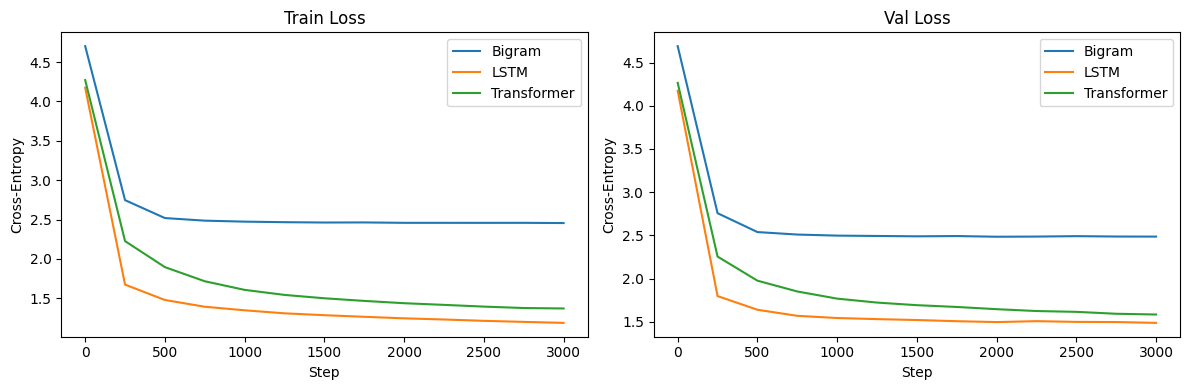

In [ ]:
from IPython.core.pylabtools import figsize
quality = {'Bigram': 'Low', 'LSTM': 'Medium', 'Transformer': 'Medium'}
notes = {'Bigram': 'Uses 1 previous character only',
        'LSTM': 'Memory carried step by step; val loss flattened at 2500',
         'Transformer': 'Attention over 128-character context; val loss continued to fall at 3000 '}
rows = ['| Model | Params | Train Loss | Val Loss | Training Time | Generated Text Quality | Notes |', '| --- | --- | --- | --- | --- | --- | --- |']

for name, r in results.items():
    rows.append(f"| {name} | {r['params']} | {r['train_loss']:.4f} | {r['val_loss']:.4f} | {r['train_time']:.1f}s | {quality[name]} | {notes[name]} | "
    f"{r['train_time']:.0f}s | {quality[name]} | {notes[name]} |")
table = '\n'.join(rows)
print(table)
open('results_table.md', 'w').write(table + '\n')

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, r in results.items():
    its = [x[0] for x in r['history']]
    ax[0].plot(its, [x[1] for x in r['history']], label=name)
    ax[1].plot(its, [x[2] for x in r['history']], label=name)

ax[0].set_title('Train Loss'); ax[1].set_title('Val Loss')
ax[0].set_xlabel('Iterations'); ax[1].set_ylabel('Train Loss')
for a in ax:
    a.set_xlabel('Step'); a.set_ylabel('Cross-Entropy'); a.legend()
plt.tight_layout(); plt.savefig('loss.png', dpi=150)

os.makedirs('samples', exist_ok=True)
for name, r in results.items():
    open(f'samples/{name}.txt', 'w').write(r['sample'])
